In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator

from typing import Union, List

import frb_functions

In [2]:
# def gaus(x,a,x0,sigma,d):
#     return -a*np.exp(-(x-x0)**2/(2*sigma**2))+d

def gaus(x, a, x0, sigma, d):
    return -a * np.exp(-(x - x0)**2 / (2 * sigma**2)) + d

1001
best dm from Gaussian fit: 464.857 +- -0.003 pc/cc
[262.4492     262.0138855  263.15994263 ... 271.09906006 256.4083252
 256.17932129]
DM value with the highest SN: 464.951 pc/cc


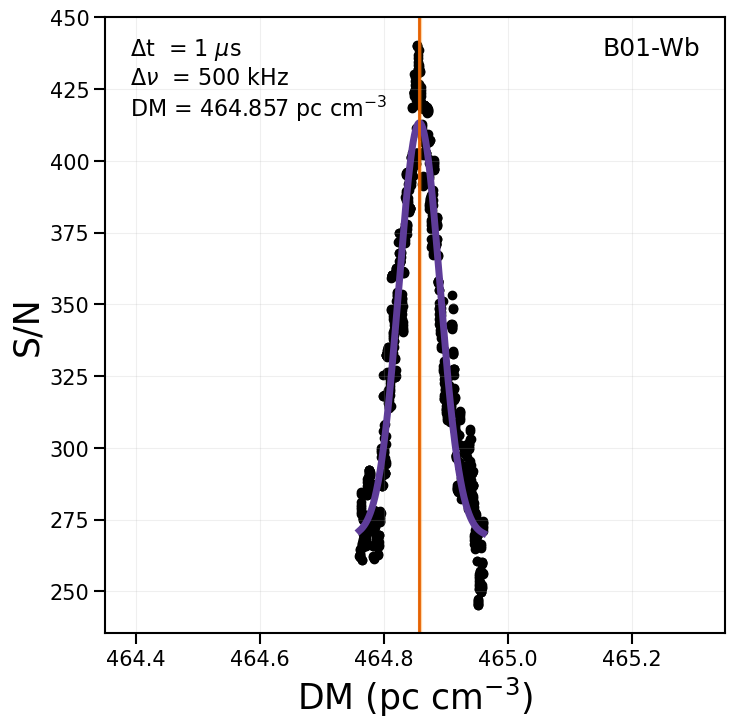

In [10]:
def sn_vs_dm_1peak(csv, obs, burst_code, tsamp, fsamp, csv_save_bool=False):

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)
    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    df = df[(df['DM'] > 464) & (df['DM'] < 466)] 
    
    sn_filter = df["sn_peak"].values
    dm_filter = df["DM"].values 
    print(len(dm_filter))
    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[-1,464.8,0.1,300], maxfev=10000)
    best_dm = poptc[1]

    sigma_3_err = 3*poptc[2]/np.sqrt(len(dm_filter))
    print(f'best dm from Gaussian fit: {best_dm:.3f} +- {sigma_3_err:.3f} pc/cc')

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)
    #Retrieving the entire grid space from the df
    sn_range = df["sn_peak"].values 
    print(sn_range)
    dm_range = df["DM"].values 

    #High peak index
    high_idx_dm = dm_range[np.argmin(sn_range)]
    print(f"DM value with the highest SN: {high_idx_dm:.3f} pc/cc")
    ##Figure
    fig,ax=plt.subplots(figsize=(8,8))
    
    #Plotting the whole range
    plt.scatter(dm_range, sn_range,color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    plt.plot(dm_space,gaus(dm_space,*poptc),color='#5e3c99',lw=5)
    
    plt.axvline(best_dm,color="#e66101", lw=2)    
    plt.axvspan(xmin=best_dm-sigma_3_err, xmax=best_dm+sigma_3_err, ymin=0, ymax=1, color='darkorange', alpha=0.25)
 
    plt.xlabel(r'DM (pc cm$^{-3})$',size=25)
    plt.ylabel('S/N',size=25)
    dm = 464.85
    offset = 0.5
    plt.xlim(dm-offset,dm+offset)
    #plt.ylim(8,16.5)
    ax.text(0.96, 0.969, f"{burst_code}", transform=ax.transAxes, fontsize=18, va='top', ha='right')   
    # ax.yaxis.set_major_locator(ticker.MultipleLocator(2.0))
    # ax.yaxis.set_minor_locator(ticker.MultipleLocator(1.0))
    # ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
    # ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.05))

    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=15, width=1.5, length=8)
        ax.tick_params(axis='both', which='minor', labelsize=15, width=1, length=5)

    plt.grid(which="both", alpha=0.2)

    ax.text(0.04, 0.969, fr"$\Delta$t  = {(tsamp):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp):.0f} kHz " + "\n" + \
             fr"DM = {best_dm:.3f}"+ r" pc cm$^{-3}$" ,\
            transform=ax.transAxes, fontsize=16, va='top', ha='left')

    plot_name = f"{obs}_{tsamp}us_{fsamp}MHz_{len(dm_filter)}steps"
    fig.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    fig.savefig(plot_name + ".png", facecolor='white', \
                transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    plt.show()

    #To make sure we save the output of the bash script, we resave the .csv file using a name convention
    if csv_save_bool == True:
        start_dm = np.min(dm_range)
        stop_dm = np.max(dm_range)
        dmstep = dm_range[1] - dm_range[0]
        csv_name = f"{obs}_{start_dm}_{stop_dm}_{dmstep:.4f}_{len(dm_filter)}steps_{tsamp}us_{fsamp}khz.csv"
        print(f"csv name: {csv_name}")
        df.to_csv(csv_name, sep=",", header=True, index=True,)
        
    return
    
sn_vs_dm_1peak("p55025_28/p55025_28_1us_1000steps_00002_peak_sn.csv", obs="p55025_28", burst_code="B01-Wb", \
               tsamp=1, fsamp=500, csv_save_bool=False)